# Librerías

In [ ]:
import matplotlib.pyplot as plt
plt.rcParams["figure.figsize"] = (8,5) #tamaño de los gráficos: ancho x alto
import numpy as np
import pandas as pd # para levantar datos desde archivos: txt, csv, otros.

#para clustering
from sklearn.cluster import KMeans
# https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html
from sklearn.cluster import DBSCAN
# https://scikit-learn.org/stable/modules/generated/sklearn.cluster.DBSCAN.html

---
# Clustering

## Charlar la idea de clustering: ¿qué es?, ¿para qué se usa?

## Charlar los tipos de clustering:

- ### Basados en centroides: por ejemplo k-means.
- ### Basados en densidad: por ejemplo DBSCAN.
- ### Basados en conectividad: por ejemplo clusterings jerárquicos (aglomerativos o divisivos).
- ### Otros: por ejemplo basados en distribuciones (mezcla de gaussianas por ejemplo).

https://en.wikipedia.org/wiki/Cluster_analysis

---

## Ejemplo: levantar los datos de `data1.csv`

1. ### Realizar el gráfico de dispersión de los datos
1. ### ¿Cuántos clusters identifica?

In [ ]:
# levantar datos
datos_df = pd.read_table('data1.csv', sep=',')
datos_df.head() #mostrar primeras 5 filas

,x,y
0,9.319049,6.406236
1,2.752240,5.609928
2,8.469910,17.636237
3,8.701497,3.632456
4,7.858546,10.899268


(400, 2)


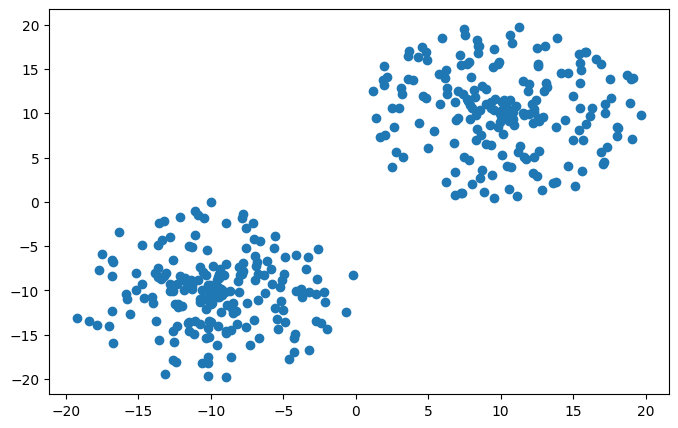

In [ ]:
datos = datos_df.to_numpy()
print(datos.shape)

plt.scatter(datos[:,0], datos[:,1], label='Datos crudos')

---
## Clustering por K-means

### Visualización interactiva: https://kkevsterrr.github.io/K-Means/

- ### Charlar la idea de k-means.
- ### Charlar porqué los clusters finales pueden depender de la elección inicial de centroides.

- ### Charlar cómo se mide cuán buena es la clusterización.
  - ### Si la cantidad de clusters aumenta, la inercia disminuye.
  - ### En particular si la cant. de clusters es igual a la cantidad de datos, el $W$ es mínimo. Pero no es la idea de k-means.
---

## Ejemplo: con los mismos datos levantados de antes

1. ### Realizar un clustering con k-means, con la cantidad de clusters observada anteriormente.
1. ### Realizar el gráfico de dispersión de los datos coloreando cada dato de acuerdo a la asignación al cluster dada por k-means del ítem anterior. Además graficar en el mismo gráfico los centroides de k-means.
1. ### Calcular el error del clustering anterior (medido con la inercia W. Comentar el ejercicio 9.c )
1. ### Justificar la elección de la cantidad de clusters por el método del "bastón quebrado" o "codo".

---
# OJO: vamos a hacer clustering con datos en 2D solamente para poder visualizarlo, pero el código sirve para datos en CUALQUIER cantidad de dimensiones.
---

[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]


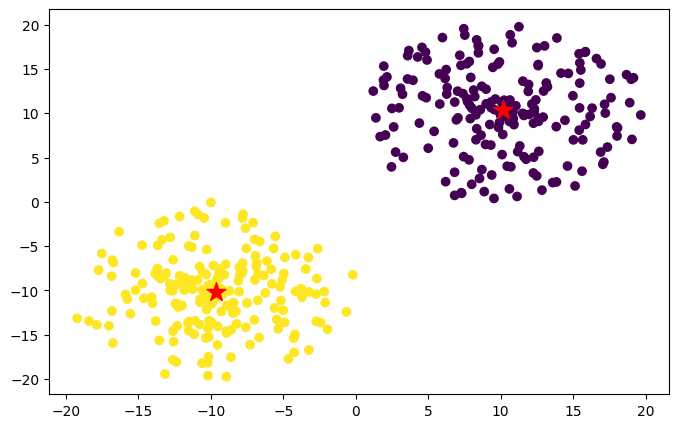

In [ ]:
# Ejecuto K-means
cant_clusters = 2

kmeans = KMeans(n_init = 10, n_clusters = cant_clusters) #el n_init es la cantidad de inicializaciones

clases = kmeans.fit_predict(datos)
# print(len(clases))
print(clases) #clase para cada dato



# grafico datos y sus asignaciones a cada cluster

plt.scatter(datos[:,0], datos[:,1], c = clases)  # La ultima opción asigna el color de
#cada punto con los colores que elige Python

# graficos los centroides
plt.scatter(kmeans.cluster_centers_[:,0], kmeans.cluster_centers_[:,1], marker='*', s=200, c='red')
plt.show()

In [ ]:
# Calculo el error cometido
W = kmeans.inertia_
print(W)

13895.13668145939


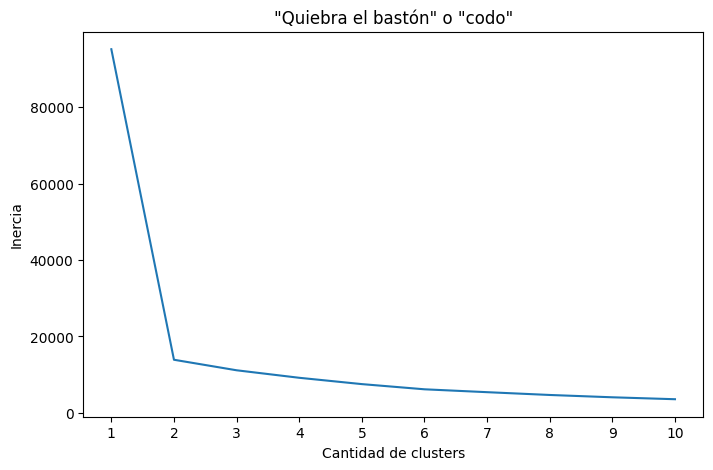

In [ ]:
# método de "codo quebrado"

valores_inercia = np.array([])
rango_clusters = np.arange(1,11,1)

for i in rango_clusters:
    # para cada valor de i, calculo kmeans y silhouette
    k_means = KMeans(n_clusters=i, n_init=10)
    k_means.fit(datos)

    valores_inercia = np.append(valores_inercia, k_means.inertia_)
    # print(i,k_means.inertia_)

plt.plot(rango_clusters, valores_inercia)
plt.xticks(rango_clusters)
plt.xlabel('Cantidad de clusters')
plt.ylabel('Inercia')
plt.title('"Quiebra el bastón" o "codo"')
plt.show()

# print(valores_inercia)

---
## Charlar ventajas y desventajas de k-means
---

---
---
---
## Clustering por DBSCAN

### Visualización interactiva: https://www.naftaliharris.com/blog/visualizing-dbscan-clustering/


- ### Charlar la idea y cómo influyen los parámetros: el épsilon y la cantidad mínima de puntos.
- ### Charlar la idea de puntos núcleo, alcanzables y ruido.
---

## Ejemplo: con los mismos datos levantados de antes, realizar un clustering por DBSCAN

1. ### Dejar fija la cantidad mínima de puntos en 3, y variar el épsilon entre 1, 2 y 3. Graficar cada caso. ¿Qué observa?, ¿cuántos clusters quedan?, ¿quedan puntos ruido (es decir fuera de cualquier cluster)?
1. ### Dejar fijo el épsilon en 3 y variar la cantidad mínima de puntos entre 5, 10 y 20. Graficar cada caso. ¿Qué observa?, ¿cuántos clusters quedan?, ¿quedan puntos ruido (es decir fuera de cualquier cluster)?

---
# OJO: vamos a hacer clustering con datos en 2D solamente para poder visulizarlo, pero el código sirve para datos en CUALQUIER cantidad de dimensiones.
---

Cantidad de clusters:
 [-1  0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22
 23 24 25 26 27 28 29 30 31 32 33 34]
Cantidad de datos por cluster:
 [117   6  62   3   3   8   6   6   3   4   3   4   4   3   3   5   4   3
   3   4  71  19   4  10   4   3   3   3   4   3   6   3   4   3   3   3]


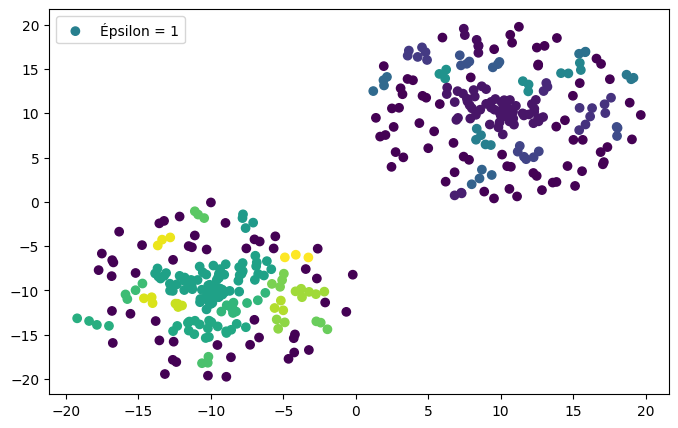

Cantidad de clusters:
 [-1  0  1  2  3]
Cantidad de datos por cluster:
 [  2 197   3 195   3]


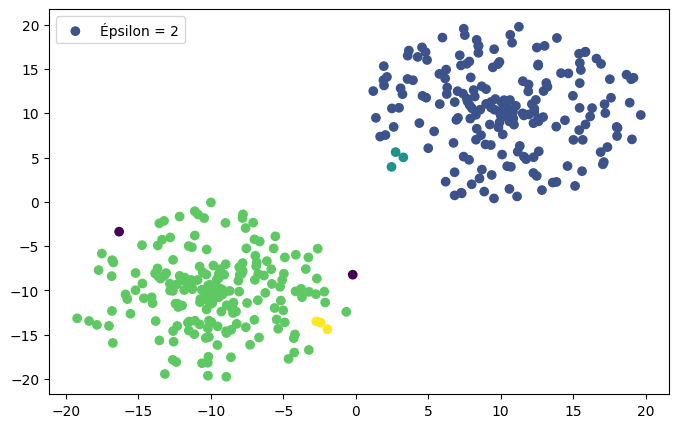

Cantidad de clusters:
 [0 1]
Cantidad de datos por cluster:
 [200 200]


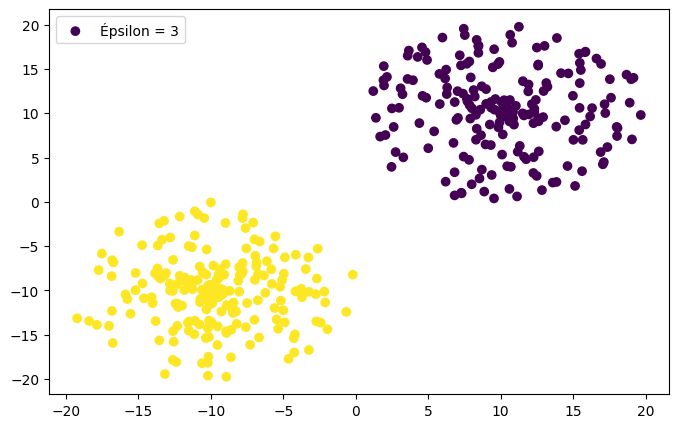

In [ ]:
valores_epsilon = np.array([1,2,3])
cant_min_puntos = 3

for epsilon in valores_epsilon:
  db = DBSCAN(eps = epsilon, min_samples = cant_min_puntos)
  clases = db.fit_predict(datos) #la clase -1 son los puntos ruido
  clusters, cantidades = np.unique(clases, return_counts=True)
  print("Cantidad de clusters:\n", clusters)
  print("Cantidad de datos por cluster:\n", cantidades)
  plt.scatter(datos[:,0], datos[:,1], c = clases, label="Épsilon = {}".format(epsilon))
  plt.legend()
  plt.show()

Cantidad de clusters:
 [0 1]
Cantidad de datos por cluster:
 [200 200]


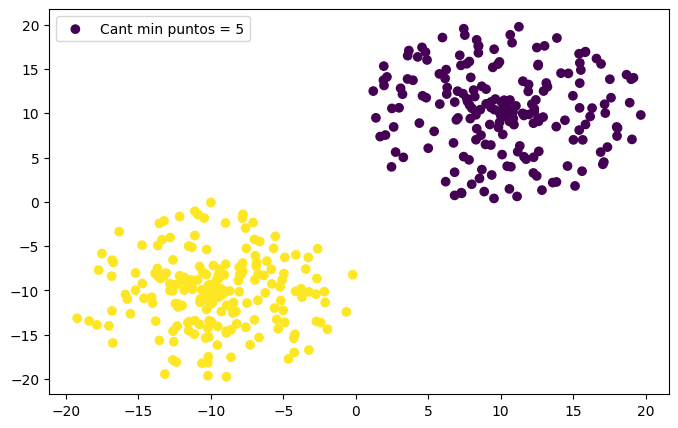

Cantidad de clusters:
 [-1  0  1]
Cantidad de datos por cluster:
 [  5 196 199]


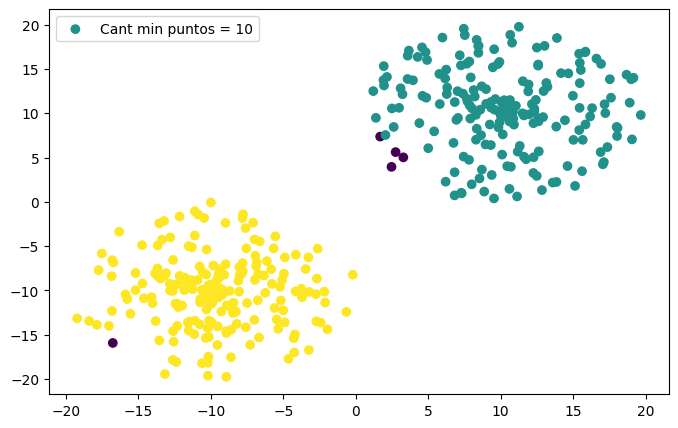

Cantidad de clusters:
 [-1  0  1]
Cantidad de datos por cluster:
 [107 131 162]


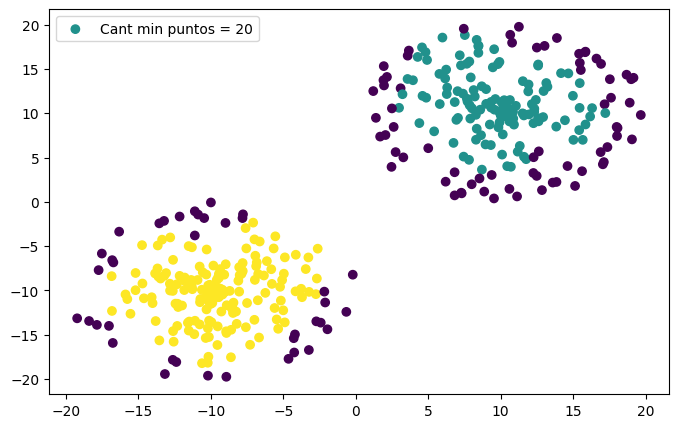

In [ ]:
epsilon = 3
valores_cant_min_puntos = np.array([5,10,20])
for cant_min_puntos in valores_cant_min_puntos:
  db = DBSCAN(eps = epsilon, min_samples = cant_min_puntos)
  clases = db.fit_predict(datos) #la clase -1 son los puntos ruido
  clusters, cantidades = np.unique(clases, return_counts=True)
  print("Cantidad de clusters:\n", clusters)
  print("Cantidad de datos por cluster:\n", cantidades)
  plt.scatter(datos[:,0], datos[:,1],c = clases, label="Cant min puntos = {}".format(cant_min_puntos))
  plt.legend()
  plt.show()

---
## Charlar ventajas y desventajas de DBSCAN
---